# Lab: Comparing Distributions Across Groups

Choose a new documented dataset with **at least one categorical feature and three quantitative features**. Develop and answer **three distinct research questions**, each comparing the distribution of a different quantitative feature across categorical groups. Use the six-step reproducible analysis workflow for each question, as in the Billboard lecture.

Your dataset must not have been used in any class demonstration or lab, including your own earlier lab submissions.


## Learning goals

- Select and document a new dataset suitable for comparing distributions.
- Distinguish meaningful quantitative measurements from identifiers and category codes.
- Develop three questions and record predictions before analyzing their results.
- Compare group sizes, center, spread, shape, overlap, and unusual observations.
- Check calculations against original records and write supported conclusions and limitations.


## The reproducible analysis workflow

1. **Question:** What do we want to learn?
2. **Data:** Which observations and features can help answer it?
3. **Evidence:** What should we calculate and display to answer the question?
4. **Check:** Does the result make sense in context? Do original records support the calculation and interpretation?
5. **Conclusion:** What claim is supported?
6. **Limitation:** What should we avoid concluding?

Complete all six steps separately for each question. Inspect the dataset once, then explain the observations, features, and preparation relevant to each investigation. Use separate code cells for individual operations and add cells as needed.


## Using AI tools responsibly

You may use AI for questions, debugging, or feedback. You remain responsible for understanding the code, reading the actual source documentation, and checking claims against your output. Disclose AI use and describe a suggestion you checked in the final reflection.


## Find and document a new dataset

Choose a manageable CSV from a documented source, such as a government open-data portal, a research repository, or Kaggle. It must have:

- A named publisher or creator and a data dictionary or equivalent feature documentation.
- At least one meaningful categorical feature with two or more groups containing multiple observations.
- At least three distinct quantitative measurements with documented meanings and units. Numeric IDs, category codes, and alternate-unit copies of the same measurement do not count as three quantitative features.
- Enough usable observations in each comparison group to examine distributions. There is no universal minimum group size for this descriptive exercise; justify exclusions and acknowledge sparse groups.
- A topic and dataset that have not already been used in class or any lab. A different filename, subset, or download of a previously used dataset does not make it new.

Review the course notebooks and your previous submissions. Examples already used include Billboard number-one songs, Titanic passengers, Pokémon, and penguins; this is not an exhaustive list.

Save the CSV in this notebook's `data` folder, use a relative path, and preserve the original records. Use a descriptive DataFrame name ending in `_df`. Your categorical feature can be reused across questions, or you may choose different categorical features for different questions.


**What are the dataset title, publisher or creator, direct source URL, data dictionary URL or location, and access date?**

Your answer:

**Dataset Title:** Auto MPG (Vehicle Fuel Efficiency)

**Publisher:** UCI Machine Learning Repository

**Creator:** R. Quinlan (1993), based on the Carnegie Mellon University StatLib dataset.

**CSV Source:** https://raw.githubusercontent.com/mwaskom/seaborn-data/master/mpg.csv

**Original Dataset Documentation:** https://archive.ics.uci.edu/dataset/9/auto+mpg

**Data Dictionary:** Available on the UCI Machine Learning Repository page under "Variables Table" and "Additional Variable Information."

**Access Date:** November 11, 2026.

**Describe the dataset: what does one row represent, what time period and population or location does it cover, and how were observations collected? State when something is undocumented.**

Your answer:  Each row represents an individual automobile model or vehicle configuration, including its fuel efficiency and mechanical specifications. The dataset contains 398 observations covering model years 1970 through 1982.

The original data comes from the Carnegie Mellon University StatLib collection and was later made available through the UCI Machine Learning Repository. It contains recorded vehicle specifications and fuel-economy measurements, including miles per gallon (MPG), engine displacement, horsepower, weight, acceleration, cylinder count, model year, and geographic origin.

The dataset is observational rather than synthetic. However, the available documentation does not fully establish how every original measurement was collected or whether the vehicles were selected through a representative sampling process.

**How did you confirm this dataset has not been used in class or any earlier lab, including your own submissions?**

Your answer:  I reviewed the datasets used in my previous assignments and compared the Auto MPG dataset against the examples identified in the course materials. The previously used datasets include Titanic passengers, Pokémon, and Billboard music data.

I selected Auto MPG because it focuses on historical automobile specifications and fuel efficiency rather than the subjects covered in those earlier exercises. I have not previously used this dataset in my lab submissions.

Based on this review, Auto MPG is a new dataset for this assignment.

## Load and inspect the data

Use separate cells to import the libraries, load the CSV, and inspect its structure. Identify special missing codes from the dictionary; distinguish them from valid zeros.


In [1]:
# Import Pandas, Matplotlib pyplot, and Seaborn with conventional aliases.
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

vehicle_df = pd.read_csv(
    "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/mpg.csv"
)

vehicle_df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


In [2]:
# Load your CSV into a descriptive DataFrame ending in _df using a relative path.
import pandas as pd
from pathlib import Path

url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/mpg.csv"

Path("data").mkdir(exist_ok=True)
pd.read_csv(url).to_csv("data/mpg.csv", index=False)

vehicle_df = pd.read_csv("data/mpg.csv")

In [3]:
# Display the first five rows.
vehicle_df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


In [4]:
# Display the last five rows.
vehicle_df.tail()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
393,27.0,4,140.0,86.0,2790,15.6,82,usa,ford mustang gl
394,44.0,4,97.0,52.0,2130,24.6,82,europe,vw pickup
395,32.0,4,135.0,84.0,2295,11.6,82,usa,dodge rampage
396,28.0,4,120.0,79.0,2625,18.6,82,usa,ford ranger
397,31.0,4,119.0,82.0,2720,19.4,82,usa,chevy s-10


In [5]:
# Display the DataFrame shape.
vehicle_df.shape

(398, 9)

In [6]:
# Display .info().
vehicle_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    object 
 8   name          398 non-null    object 
dtypes: float64(4), int64(3), object(2)
memory usage: 28.1+ KB


In [7]:
# Display missing-value counts for every feature.
vehicle_df.isnull().sum()

mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
name            0
dtype: int64

### Document the features

Complete one row for **every feature**. Add rows as needed. For data type, use categorical or quantitative, and explicitly identify identifiers and temporal features where appropriate. Report the actual Pandas storage type separately.


| Feature | Meaning and units or category codes | Data type | Data storage type | Missing values |
|---|---|---|---|---:|
| mpg | Fuel efficiency in miles per gallon (MPG) | Quantitative | float64 | 0 |
| cylinders | Number of engine cylinders (3, 4, 5, 6, or 8) | Categorical (discrete count) | int64 | 0 |
| displacement | Engine displacement in cubic inches | Quantitative | float64 | 0 |
| horsepower | Engine power in horsepower (hp) | Quantitative | float64 | 6 |
| weight | Vehicle weight in pounds (lb) | Quantitative | int64 | 0 |
| acceleration | Time to accelerate from 0 to 60 mph, in seconds | Quantitative | float64 | 0 |
| model_year | Model year, 1970–1982 | Temporal | int64 | 0 |
| origin | Vehicle origin: USA, Europe, Japan | Categorical | object | 0 |
| name | Vehicle make and model | Identifier / Categorical text | object | 0 |

**Which categorical feature(s) and three quantitative features will you analyze? Why are they appropriate for distribution comparisons? Explain any missing codes or conversions.**

Your answer:  I will use **vehicle origin** as my categorical feature, comparing automobiles manufactured in the USA, Europe, and Japan.

I will analyze three quantitative features:

1. **Fuel efficiency (mpg):** Measured in miles per gallon, allowing me to compare fuel economy across the three regions.
2. **Vehicle weight (weight):** Measured in pounds, allowing me to compare the distribution of vehicle sizes and weights across regions.
3. **Engine displacement (displacement):** Measured in cubic inches, allowing me to compare engine sizes across regions.

These features are appropriate because they represent three distinct, measurable characteristics of automobile performance and engineering. Comparing their distributions across geographic origins may reveal differences in automotive design priorities during the 1970–1982 model years.

The dataset contains six missing horsepower values, but none of the three selected quantitative features or the origin categories contain missing values. Therefore, no records need to be excluded or imputed for these comparisons.

The original model-year codes represent 1970–1982, but model year is not needed for my three primary comparisons. No unit conversions or missing-value replacements are required.

## Plan three investigations

Write three specific questions. **Use a different quantitative feature for each question**, covering at least three in total. Each question must compare that feature's distribution across at least two categorical groups. You may reuse the same grouping feature. Changing only the plot type does not create a new question.

A useful question pattern is: “How does the distribution of [measurement and units] differ among [groups] in [documented population or period]?” Adapt it to your dataset's meaning. Similar distributions are a valid result; do not search for differences by repeatedly changing groups or discarding records.


## Investigation 1

### Step 1: Question


**What is research question 1? Name the quantitative feature, its units, and the categorical groups.**

Your answer:  How does the distribution of fuel efficiency, measured in miles per gallon (MPG), differ among automobiles originating from the USA, Europe, and Japan during the 1970–1982 model years?

I want to determine whether vehicles from these three regions show meaningful differences in typical fuel economy, variability, and overall distribution. This comparison may reveal how automotive engineering and design characteristics differed across regions during this period.

**Before calculating or plotting, what do you predict about center, spread, shape, or overlap? Why?**

Your answer:  I predict that Japanese vehicles will have the highest typical fuel efficiency (MPG), followed by European vehicles, with American vehicles having the lowest typical MPG.

I expect American vehicles to show a wider spread in fuel efficiency because of the greater variety of vehicle sizes and engine configurations represented in the dataset. I anticipate Japanese and European vehicles will have somewhat tighter distributions, with more observations concentrated at higher MPG values.

I also expect considerable overlap among the three regions because all three produced vehicles with different engine sizes, weights, and performance characteristics.

My reasoning is that smaller, lighter vehicles generally require less energy to move, while larger vehicles with higher-displacement engines often consume more fuel. These are predictions based on automotive engineering principles, not conclusions drawn from the dataset.

### Step 2: Data

Reuse the initial inspection. Define this question's observations and groups before generating evidence. Preserve the original DataFrame and explain any filtering, conversions, or derived labels.


**Which records and features will you use? Define group labels and units, explain missing-value handling and exclusions, and state what one analyzed observation represents.**

Your answer:  For this investigation, I will use all 398 automobile records in the Auto MPG dataset, covering model years 1970 through 1982.

I will analyze two features:

- **origin (categorical):** Groups vehicles into USA, Europe, and Japan.
- **mpg (quantitative):** Measures fuel efficiency in miles per gallon.

Each observation represents one automobile model or vehicle configuration with its recorded fuel efficiency and geographic origin.

I will compare the MPG distributions of American, European, and Japanese vehicles using the same original records.

There are no missing values in either `origin` or `mpg`, so all 398 records can be included. No missing-value replacements, unit conversions, or exclusions are necessary.

I will preserve the original `vehicle_df` DataFrame and create a separate analysis DataFrame containing the two selected features. This keeps the analysis reproducible without modifying the original dataset.

In [8]:
# Prepare this question's analysis DataFrame and preview the selected features.

# Select vehicle origin and fuel efficiency.
mpg_analysis_df = vehicle_df[["origin", "mpg"]].copy()

# Display the first five observations.
mpg_analysis_df.head()

,origin,mpg
0,usa,18.0
1,usa,15.0
2,usa,18.0
3,usa,16.0
4,usa,17.0


In [9]:
# Display the number of usable observations in each group.
mpg_analysis_df.groupby("origin")["mpg"].count()

origin
europe     70
japan      79
usa       249
Name: mpg, dtype: int64

### Step 3: Evidence

Create a **histogram comparison and a box-plot comparison** for this quantitative feature using the same observations and group definitions. A violin plot is optional. Use descriptive titles, units, readable labels, a consistent group order, and named colors. Keep group colors consistent across plots. Use shared histogram bins; use whole-number bins when appropriate for discrete counts. Label whether the vertical axis shows counts or another documented scale.

Start with the histogram and estimate the distributions visually. Then calculate group summaries and use the box plot to compare them. Retain valid extreme observations; do not remove them just to make figures look cleaner.


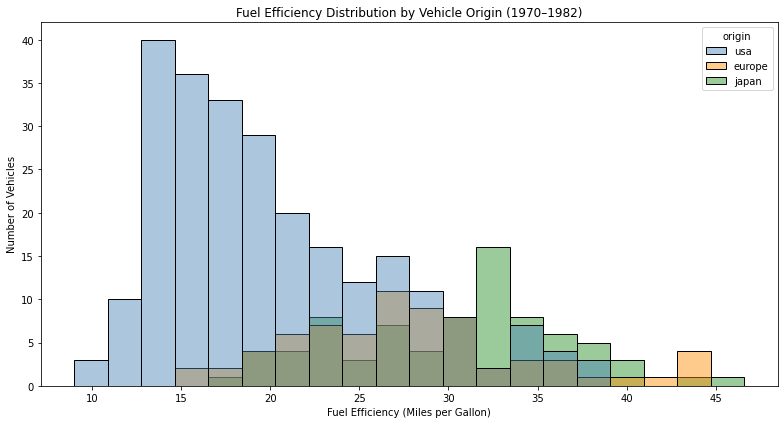

In [10]:
# Create and label the histogram comparison.
# Compare fuel-efficiency distributions by vehicle origin.
origin_order = ["usa", "europe", "japan"]

origin_colors = {
    "usa": "steelblue",
    "europe": "darkorange",
    "japan": "forestgreen"
}

plt.figure(figsize=(11, 6))

sns.histplot(
    data=mpg_analysis_df,
    x="mpg",
    hue="origin",
    hue_order=origin_order,
    palette=origin_colors,
    bins=20,
    multiple="layer",
    alpha=0.45,
    common_bins=True
)

plt.title("Fuel Efficiency Distribution by Vehicle Origin (1970–1982)")
plt.xlabel("Fuel Efficiency (Miles per Gallon)")
plt.ylabel("Number of Vehicles")
plt.tight_layout()
plt.show()

**From the histogram, estimate each group's typical values and spread. Describe shape, overlap, and unusual observations. How do group sizes affect the comparison?**

Your answer:  The histogram suggests that vehicles from Japan generally have higher fuel efficiency than vehicles from the USA, while European vehicles fall between the two groups, with substantial overlap.

**USA:** Most vehicles appear concentrated around 15–25 MPG, with a broader distribution extending into higher fuel-efficiency values. The distribution appears somewhat right-skewed.

**Europe:** Many vehicles appear concentrated around 20–35 MPG, although the distribution includes both lower-efficiency vehicles and some unusually efficient models.

**Japan:** Most vehicles appear concentrated around 25–35 MPG, with some vehicles exceeding 40 MPG. The distribution overlaps considerably with the European vehicles.

The three groups overlap, especially between approximately 20 and 35 MPG, indicating that geographic origin alone does not determine a vehicle's fuel efficiency.

The USA has substantially more observations than either Europe or Japan. Because the histogram displays vehicle counts, larger groups may produce taller bars simply because they contain more records. Therefore, I need to consider group sizes when comparing the distributions.

These are approximate visual estimates that will be checked against numerical summaries in the next step.

In [11]:
# Display grouped .describe() summaries and calculate or display the IQR for each group.
# Calculate descriptive statistics for MPG by vehicle origin.
mpg_summary = mpg_analysis_df.groupby("origin")["mpg"].describe()

# Calculate the interquartile range (IQR).
mpg_summary["IQR"] = mpg_summary["75%"] - mpg_summary["25%"]

# Display results in a consistent group order.
mpg_summary.loc[origin_order].round(2)

,count,mean,std,min,25%,50%,75%,max,IQR
origin,,,,,,,,,
usa,249.0,20.08,6.40,9.0,15.0,18.5,24.00,39.0,9.00
europe,70.0,27.89,6.72,16.2,24.0,26.5,30.65,44.3,6.65
japan,79.0,30.45,6.09,18.0,25.7,31.6,34.05,46.6,8.35


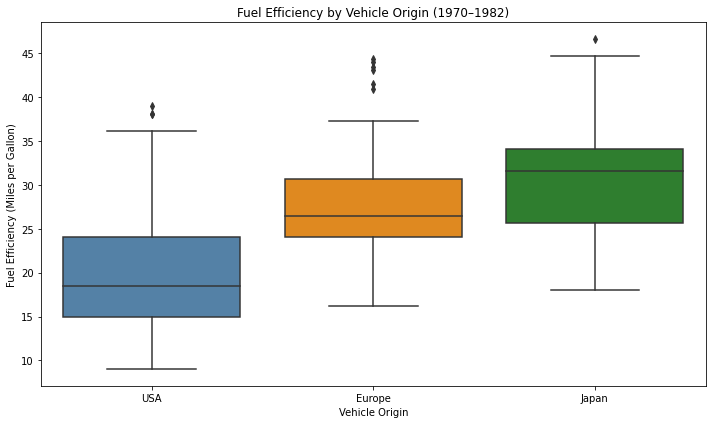

In [12]:
# Create and label the box-plot comparison.
# Compare fuel-efficiency distributions by vehicle origin.
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=mpg_analysis_df,
    x="origin",
    y="mpg",
    order=origin_order,
    palette=origin_colors
)

plt.title("Fuel Efficiency by Vehicle Origin (1970–1982)")
plt.xlabel("Vehicle Origin")
plt.ylabel("Fuel Efficiency (Miles per Gallon)")
plt.xticks([0, 1, 2], ["USA", "Europe", "Japan"])

plt.tight_layout()
plt.show()

**How do the calculated summaries compare with your visual estimates? Which groups look similar or different? Cite centers and spreads with units, and explain what each plot reveals or hides.**

Your answer:  The calculated statistics generally support my initial observations from the histogram. Japanese vehicles have the highest typical fuel efficiency, followed by European vehicles, while American vehicles have the lowest.

**USA (249 vehicles):**
- Mean: 20.08 MPG
- Median: 18.50 MPG
- Standard deviation: 6.40 MPG
- IQR: 9.00 MPG
- Range: 9.0–39.0 MPG

**Europe (70 vehicles):**
- Mean: 27.89 MPG
- Median: 26.50 MPG
- Standard deviation: 6.72 MPG
- IQR: 6.65 MPG
- Range: 16.2–44.3 MPG

**Japan (79 vehicles):**
- Mean: 30.45 MPG
- Median: 31.60 MPG
- Standard deviation: 6.09 MPG
- IQR: 8.35 MPG
- Range: 18.0–46.6 MPG

The median fuel efficiency of Japanese vehicles is 13.10 MPG higher than that of American vehicles. European vehicles fall between the two groups, with a median of 26.50 MPG.

American vehicles have the largest interquartile range at 9.00 MPG, indicating greater variability in the middle 50% of observations. European vehicles have the smallest IQR at 6.65 MPG, although their standard deviation is slightly larger than that of the other groups. This shows why examining multiple measures of spread is important.

The histogram reveals the overall shape of each distribution, areas where vehicles are concentrated, and overlap between regions. However, overlapping bars and unequal group sizes can make comparisons difficult.

The box plot makes the differences in medians, quartiles, and potential outliers easier to compare, but it hides some details about the distribution shapes and concentrations.

Both visualizations demonstrate substantial overlap in fuel efficiency across the regions. Although Japanese vehicles generally achieve higher MPG values in this historical dataset, geographic origin alone does not explain every vehicle's fuel efficiency.

### Step 4: Check

Perform a sanity check connected to this question. Inspect original records for unusual values, verify any group boundaries or conversions, and reconcile group counts with the selected data. Consider plausible units, whether zero or negative values are valid, and whether the plotted range matches the numerical summary. Do not simply repeat the initial missing-value count.


In [13]:
# Perform a targeted check against original records or the declared group definitions.
# Verify the original records, group counts, and MPG values.

# Confirm the three vehicle-origin groups.
print("Vehicle counts by origin:")
print(vehicle_df["origin"].value_counts())

# Verify that MPG values are positive and not missing.
print("\nMissing MPG values:", vehicle_df["mpg"].isna().sum())
print("Zero or negative MPG values:", (vehicle_df["mpg"] <= 0).sum())

# Check the vehicles with the lowest and highest MPG.
print("\nFive lowest-MPG vehicles:")
display(
    vehicle_df.nsmallest(5, "mpg")[
        ["name", "origin", "model_year", "mpg", "weight", "displacement"]
    ]
)

print("\nFive highest-MPG vehicles:")
display(
    vehicle_df.nlargest(5, "mpg")[
        ["name", "origin", "model_year", "mpg", "weight", "displacement"]
    ]
)

Vehicle counts by origin:
usa       249
japan      79
europe     70
Name: origin, dtype: int64

Missing MPG values: 0
Zero or negative MPG values: 0

Five lowest-MPG vehicles:


,name,origin,model_year,mpg,weight,displacement
28,hi 1200d,usa,70,9.0,4732,304.0
25,ford f250,usa,70,10.0,4615,360.0
26,chevy c20,usa,70,10.0,4376,307.0
27,dodge d200,usa,70,11.0,4382,318.0
67,mercury marquis,usa,72,11.0,4633,429.0



Five highest-MPG vehicles:


,name,origin,model_year,mpg,weight,displacement
322,mazda glc,japan,80,46.6,2110,86.0
329,honda civic 1500 gl,japan,80,44.6,1850,91.0
325,vw rabbit c (diesel),europe,80,44.3,2085,90.0
394,vw pickup,europe,82,44.0,2130,97.0
326,vw dasher (diesel),europe,80,43.4,2335,90.0


**What would make you suspicious, and why? What did your check establish? Describe any correction or unresolved uncertainty.**

Your answer:  I performed a sanity check against the original Auto MPG records to verify that the fuel-efficiency measurements and vehicle-origin groups were reasonable.

Several issues would make me suspicious of the analysis, including zero or negative MPG values, missing fuel-efficiency measurements, unexpected geographic categories, or extreme values that could indicate recording errors.

The check confirmed that the dataset contains 249 American vehicles, 70 European vehicles, and 79 Japanese vehicles, totaling 398 observations. There were no missing MPG values and no zero or negative fuel-efficiency measurements.

I also examined the five vehicles with the lowest MPG values and the five with the highest MPG values, including their names, origins, model years, weights, and engine displacements. The extremes are consistent with the broader pattern that heavier vehicles with larger engines often have lower fuel efficiency, while smaller vehicles tend to achieve higher MPG values.

No corrections or exclusions were necessary for this investigation. However, the original documentation does not fully establish the measurement procedures or sampling methods, so I cannot independently verify every recorded value.

### Step 5: Conclusion


**Answer your research question using group sizes, center, spread, and overlap. Cite numerical evidence with units. How does it compare with your prediction?**

Your answer:  The analysis shows that fuel efficiency differed substantially among American, European, and Japanese automobiles from 1970 through 1982.

**American vehicles (249 observations)** had the lowest typical fuel efficiency, with a median of 18.50 MPG, a mean of approximately 20.08 MPG, and an interquartile range (IQR) of 9.00 MPG.

**European vehicles (70 observations)** had higher fuel efficiency, with a median of 26.50 MPG, a mean of approximately 27.89 MPG, and an IQR of 6.65 MPG.

**Japanese vehicles (79 observations)** demonstrated the highest typical fuel efficiency, with a median of 31.60 MPG, a mean of approximately 30.45 MPG, and an IQR of 8.35 MPG.

The difference between the Japanese and American medians was 13.10 MPG, indicating a substantial difference in typical fuel efficiency within this dataset.

Although the three groups have different centers, their distributions overlap. Some American vehicles achieved fuel-efficiency values comparable to European and Japanese vehicles, while some European and Japanese vehicles had relatively low MPG values.

These results support my original prediction that Japanese vehicles would generally achieve the highest fuel efficiency, followed by European and American vehicles. My prediction about variation was also partially supported, as American vehicles had the largest IQR, although European vehicles had a slightly larger standard deviation.

Overall, the evidence demonstrates an association between vehicle origin and fuel-efficiency distributions during this historical period, but it does not establish that geographic origin itself caused the differences.

### Step 6: Limitation


**What should a reader avoid concluding, and why? Connect the limitation to this question and dataset.**

Your answer:  Although the analysis reveals differences in fuel efficiency among American, European, and Japanese automobiles, several limitations must be considered.

First, the dataset covers vehicles from 1970 through 1982. These findings describe historical automotive engineering and should not be used to make conclusions about modern vehicles or current manufacturers.

Second, the dataset is observational. Differences in fuel efficiency may be associated with vehicle weight, engine displacement, engine configuration, model year, and other engineering characteristics. Geographic origin alone cannot be identified as the cause of the differences.

Third, the groups contain unequal numbers of observations: 249 American vehicles, 70 European vehicles, and 79 Japanese vehicles. This imbalance must be considered when comparing histogram counts and interpreting the distributions.

Additionally, the dataset documentation does not fully establish the sampling procedures or measurement methods. Therefore, the records should not automatically be considered representative of every automobile manufactured during this period.

Finally, the considerable overlap among the distributions demonstrates that individual vehicles cannot be accurately characterized by their geographic origin alone.

**The appropriate conclusion is that fuel-efficiency distributions differ by vehicle origin within this historical dataset, not that one region inherently produces more efficient vehicles under all circumstances.**

## Investigation 2

### Step 1: Question


**What is research question 2? Name the quantitative feature, its units, and the categorical groups.**

Your answer:  How does the distribution of vehicle weight, measured in pounds (lb), differ among automobiles originating from the USA, Europe, and Japan during the 1970–1982 model years?

I want to investigate whether American, European, and Japanese vehicles differ in their typical weights, variability, and overall distributions.

This comparison will help me understand differences in vehicle design and engineering characteristics across the three regions. It may also provide additional context for the fuel-efficiency differences observed in Investigation 1.

**Before calculating or plotting, what do you predict about center, spread, shape, or overlap? Why?**

Your answer:  I predict that American automobiles will have the highest typical vehicle weight, followed by European vehicles, with Japanese vehicles generally being the lightest.

I expect the American vehicles to have a higher median weight and a wider distribution because the dataset includes larger sedans, station wagons, trucks, and vehicles with larger engine configurations.

I anticipate that Japanese vehicles will have a lower median weight and a somewhat narrower distribution because many Japanese vehicles during this period were designed as smaller, fuel-efficient automobiles. European vehicles will likely fall between the two groups.

I also expect some overlap among the three distributions because manufacturers in every region produced vehicles of different sizes and purposes.

These predictions are based on general automotive engineering characteristics and the historical differences in vehicle design, rather than on calculated statistics from this investigation.

### Step 2: Data

Reuse the initial inspection. Define this question's observations and groups before generating evidence. Preserve the original DataFrame and explain any filtering, conversions, or derived labels.


**Which records and features will you use? Define group labels and units, explain missing-value handling and exclusions, and state what one analyzed observation represents.**

Your answer:  For this investigation, I will use all 398 automobile records in the Auto MPG dataset, covering model years 1970 through 1982.

I will analyze two features:

- **origin (categorical):** Groups vehicles into USA, Europe, and Japan.
- **weight (quantitative):** Measures vehicle weight in pounds (lb).

Each observation represents one automobile model or vehicle configuration with its recorded weight and geographic origin.

The dataset contains 249 American vehicles, 70 European vehicles, and 79 Japanese vehicles. I will compare the distributions of vehicle weight across these three groups, examining typical values, variability, distribution shape, and overlap.

There are no missing values in either `origin` or `weight`, so all 398 records can be included without imputation or exclusions.

No unit conversions are necessary because all vehicle weights are recorded in pounds.

I will preserve the original `vehicle_df` DataFrame and create a separate analysis DataFrame containing the selected features. This will allow me to investigate vehicle weight without modifying the original dataset.

In [14]:
# Prepare this question's analysis DataFrame and preview the selected features.
# Select vehicle origin and weight.
weight_analysis_df = vehicle_df[["origin", "weight"]].copy()

# Display the first five observations.
weight_analysis_df.head()

,origin,weight
0,usa,3504
1,usa,3693
2,usa,3436
3,usa,3433
4,usa,3449


In [15]:
# Display the number of usable observations in each group.
# Count vehicles with valid weight measurements by origin.
weight_analysis_df.groupby("origin")["weight"].count().loc[origin_order]

origin
usa       249
europe     70
japan      79
Name: weight, dtype: int64

### Step 3: Evidence

Create a **histogram comparison and a box-plot comparison** for this quantitative feature using the same observations and group definitions. A violin plot is optional. Use descriptive titles, units, readable labels, a consistent group order, and named colors. Keep group colors consistent across plots. Use shared histogram bins; use whole-number bins when appropriate for discrete counts. Label whether the vertical axis shows counts or another documented scale.

Start with the histogram and estimate the distributions visually. Then calculate group summaries and use the box plot to compare them. Retain valid extreme observations; do not remove them just to make figures look cleaner.


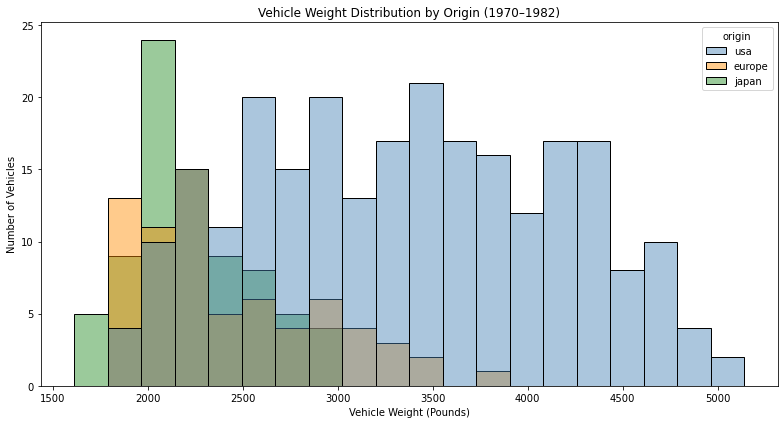

In [16]:
# Create and label the histogram comparison.
# Compare vehicle-weight distributions by origin.
plt.figure(figsize=(11, 6))

sns.histplot(
    data=weight_analysis_df,
    x="weight",
    hue="origin",
    hue_order=origin_order,
    palette=origin_colors,
    bins=20,
    multiple="layer",
    alpha=0.45,
    common_bins=True
)

plt.title("Vehicle Weight Distribution by Origin (1970–1982)")
plt.xlabel("Vehicle Weight (Pounds)")
plt.ylabel("Number of Vehicles")

plt.tight_layout()
plt.show()

**From the histogram, estimate each group's typical values and spread. Describe shape, overlap, and unusual observations. How do group sizes affect the comparison?**

Your answer:  The histogram suggests that American automobiles generally have higher vehicle weights than European and Japanese automobiles during the 1970–1982 period.

**USA:** Most vehicles appear concentrated between approximately 3,000 and 4,500 pounds. The distribution is relatively broad, reflecting the variety of vehicle sizes represented in the dataset.

**Europe:** Most vehicles appear concentrated between approximately 1,800 and 3,000 pounds, although some heavier European vehicles extend beyond this range. The distribution appears somewhat right-skewed.

**Japan:** Most vehicles appear concentrated between approximately 1,800 and 2,800 pounds. Japanese vehicles appear to have the lowest typical weights, with a somewhat narrower distribution than American vehicles.

There is substantial overlap among the three groups, particularly between approximately 2,000 and 3,000 pounds. This indicates that automobiles from different geographic regions can have similar weights despite differences in their overall distributions.

Some unusually heavy American vehicles and relatively heavy European and Japanese vehicles appear near the upper ends of their distributions.

The group sizes also affect the histogram. The dataset contains 249 American vehicles, 70 European vehicles, and 79 Japanese vehicles. Because the vertical axis represents vehicle counts, the larger American group can produce taller bars simply because it has more observations.

These are preliminary visual estimates. I will compare them against calculated descriptive statistics to determine whether the observed differences in typical weight and variability are supported by numerical evidence.

In [17]:
# Display grouped .describe() summaries and calculate or display the IQR for each group.
# Calculate descriptive statistics for vehicle weight by origin.
weight_summary = weight_analysis_df.groupby("origin")["weight"].describe()

# Calculate the interquartile range (IQR).
weight_summary["IQR"] = weight_summary["75%"] - weight_summary["25%"]

# Display results in a consistent group order.
weight_summary.loc[origin_order].round(2)

,count,mean,std,min,25%,50%,75%,max,IQR
origin,,,,,,,,,
usa,249.0,3361.93,794.79,1800.0,2720.00,3365.0,4054.00,5140.0,1334.0
europe,70.0,2423.30,490.04,1825.0,2067.25,2240.0,2769.75,3820.0,702.5
japan,79.0,2221.23,320.50,1613.0,1985.00,2155.0,2412.50,2930.0,427.5


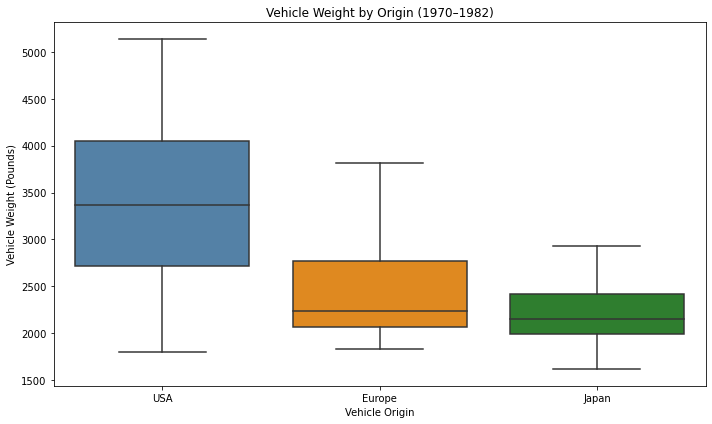

In [18]:
# Create and label the box-plot comparison.
# Compare vehicle-weight distributions by origin.
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=weight_analysis_df,
    x="origin",
    y="weight",
    order=origin_order,
    palette=origin_colors
)

plt.title("Vehicle Weight by Origin (1970–1982)")
plt.xlabel("Vehicle Origin")
plt.ylabel("Vehicle Weight (Pounds)")
plt.xticks([0, 1, 2], ["USA", "Europe", "Japan"])

plt.tight_layout()
plt.show()

**How do the calculated summaries compare with your visual estimates? Which groups look similar or different? Cite centers and spreads with units, and explain what each plot reveals or hides.**

Your answer:  The calculated statistics support my original prediction that American automobiles were generally heavier than European and Japanese automobiles during the 1970–1982 period.

**USA (249 vehicles):**
- Mean: 3,361.93 pounds
- Median: 3,365 pounds
- Standard deviation: 794.79 pounds
- IQR: 1,334 pounds
- Range: 1,800–5,140 pounds

**Europe (70 vehicles):**
- Mean: 2,423.30 pounds
- Median: 2,240 pounds
- Standard deviation: 490.04 pounds
- IQR: 702.50 pounds
- Range: 1,825–3,820 pounds

**Japan (79 vehicles):**
- Mean: 2,221.23 pounds
- Median: 2,155 pounds
- Standard deviation: 320.50 pounds
- IQR: 427.50 pounds
- Range: 1,613–2,930 pounds

American vehicles had the highest median weight at 3,365 pounds, approximately 1,210 pounds heavier than the Japanese median and 1,125 pounds heavier than the European median.

The American group also had the greatest variability, with an IQR of 1,334 pounds. Japanese vehicles showed the smallest variation, with an IQR of 427.50 pounds.

European and Japanese vehicles had more similar typical weights, although European vehicles displayed greater variability and included some substantially heavier models.

The histogram reveals where vehicle weights are concentrated, the overall distribution shapes, and areas of overlap. It also shows that the American distribution spans a wider range of weights.

The box plot provides a clearer comparison of medians, quartiles, and potential outliers, but does not display the detailed distribution shapes or clusters visible in the histogram.

Although the three groups have different typical weights, their distributions overlap, particularly between approximately 2,000 and 3,000 pounds.

These results support my initial prediction that American vehicles would generally be heaviest and Japanese vehicles lightest. They also provide additional context for Investigation 1, where American vehicles demonstrated lower typical fuel efficiency.

### Step 4: Check

Perform a sanity check connected to this question. Inspect original records for unusual values, verify any group boundaries or conversions, and reconcile group counts with the selected data. Consider plausible units, whether zero or negative values are valid, and whether the plotted range matches the numerical summary. Do not simply repeat the initial missing-value count.


In [19]:
# Perform a targeted check against original records or the declared group definitions.

# Verify group counts and vehicle-weight measurements.
print("Vehicle counts by origin:")
print(vehicle_df["origin"].value_counts())

# Check for missing or invalid vehicle weights.
print("\nMissing weights:", vehicle_df["weight"].isna().sum())
print("Zero or negative weights:", (vehicle_df["weight"] <= 0).sum())

# Inspect the five lightest vehicles.
print("\nFive lightest vehicles:")
display(
    vehicle_df.nsmallest(5, "weight")[
        ["name", "origin", "model_year", "weight", "displacement", "mpg"]
    ]
)

# Inspect the five heaviest vehicles.
print("\nFive heaviest vehicles:")
display(
    vehicle_df.nlargest(5, "weight")[
        ["name", "origin", "model_year", "weight", "displacement", "mpg"]
    ]
)

# Confirm the analyzed records match the original data.
print("\nTotal analyzed observations:", len(weight_analysis_df))

Vehicle counts by origin:
usa       249
japan      79
europe     70
Name: origin, dtype: int64

Missing weights: 0
Zero or negative weights: 0

Five lightest vehicles:


,name,origin,model_year,weight,displacement,mpg
54,datsun 1200,japan,71,1613,72.0,35.0
144,toyota corona,japan,74,1649,76.0,31.0
343,toyota starlet,japan,81,1755,79.0,39.1
345,honda civic 1300,japan,81,1760,81.0,35.1
53,toyota corolla 1200,japan,71,1773,71.0,31.0



Five heaviest vehicles:


,name,origin,model_year,weight,displacement,mpg
44,pontiac safari (sw),usa,71,5140,400.0,13.0
103,chevrolet impala,usa,73,4997,400.0,11.0
42,dodge monaco (sw),usa,71,4955,383.0,12.0
90,mercury marquis brougham,usa,73,4952,429.0,12.0
95,buick electra 225 custom,usa,73,4951,455.0,12.0



Total analyzed observations: 398


**What would make you suspicious, and why? What did your check establish? Describe any correction or unresolved uncertainty.**

Your answer:  I performed a sanity check against the original Auto MPG records to verify the vehicle-weight measurements and geographic group assignments.

I would be suspicious of missing weights, zero or negative weights, unusually extreme measurements, or vehicle records assigned to unexpected geographic categories. These issues could indicate data-entry errors, incorrect units, or problems with the analysis.

The check confirmed that the dataset contains 249 American vehicles, 70 European vehicles, and 79 Japanese vehicles, totaling 398 observations. There were no missing, zero, or negative vehicle-weight measurements.

I also inspected the five lightest and five heaviest vehicles, comparing their names, origins, model years, engine displacements, fuel efficiency, and recorded weights. The extremes were consistent with the general relationship between vehicle size, engine characteristics, and weight.

No data corrections or exclusions were necessary. However, the original dataset documentation does not fully explain how vehicle weights were measured or how the automobiles were selected, so I cannot independently verify every recorded value.

The analysis therefore retains all 398 observations and acknowledges those remaining uncertainties.

### Step 5: Conclusion


**Answer your research question using group sizes, center, spread, and overlap. Cite numerical evidence with units. How does it compare with your prediction?**

Your answer:  The analysis demonstrates substantial differences in vehicle-weight distributions among American, European, and Japanese automobiles manufactured during the 1970–1982 model years.

**American vehicles (249 observations)** had the highest typical weight, with a median of 3,365 pounds, a mean of approximately 3,361.93 pounds, and an interquartile range (IQR) of 1,334 pounds.

**European vehicles (70 observations)** had a median weight of 2,240 pounds, a mean of approximately 2,423.30 pounds, and an IQR of 702.50 pounds.

**Japanese vehicles (79 observations)** had the lowest typical weight, with a median of 2,155 pounds, a mean of approximately 2,221.23 pounds, and an IQR of 427.50 pounds.

The difference between American and Japanese median vehicle weights was approximately 1,210 pounds. American vehicles also showed considerably greater variability, while Japanese vehicles had the narrowest middle 50% of recorded weights.

European and Japanese vehicles were more similar in their typical weights, although European vehicles displayed greater variation.

Despite these differences, the distributions overlapped, especially between approximately 2,000 and 3,000 pounds. Therefore, vehicle origin alone cannot reliably predict the weight of an individual automobile.

The results support my original prediction that American automobiles would generally be the heaviest and Japanese automobiles the lightest. My prediction concerning variability was also supported, with American vehicles displaying the largest IQR and overall range.

These findings also help explain the fuel-efficiency patterns observed in Investigation 1. Vehicle weight may contribute to differences in fuel consumption, although this analysis does not establish a causal relationship.

Overall, the dataset demonstrates an association between geographic origin and vehicle-weight distributions during this historical period.

### Step 6: Limitation


**What should a reader avoid concluding, and why? Connect the limitation to this question and dataset.**

Your answer:  Although the analysis reveals differences in vehicle weight among American, European, and Japanese automobiles, several limitations must be considered.

First, the dataset covers model years 1970 through 1982. These results describe historical automotive design and should not be generalized to modern vehicles or current manufacturing practices.

Second, vehicle origin is not necessarily the direct cause of differences in weight. Vehicle class, engine size, intended use, construction materials, and manufacturer design decisions can all influence vehicle weight. This observational analysis cannot isolate the effects of these factors.

Third, the dataset contains unequal group sizes: 249 American vehicles, 70 European vehicles, and 79 Japanese vehicles. Larger groups can produce taller histogram bars because they contain more observations, not necessarily because their distributions are more concentrated.

Additionally, the dataset includes different types of vehicles, such as compact cars, sedans, station wagons, and trucks. Comparing these vehicles without controlling for vehicle class may exaggerate differences associated with geographic origin.

The original documentation also does not fully establish how the vehicles were sampled or how their weights were measured. Therefore, I cannot assume that the dataset represents every vehicle manufactured during this period.

Finally, the distributions overlap. Although American vehicles generally have higher recorded weights, individual American, European, and Japanese vehicles can have similar weights.

**The supported conclusion is that vehicle-weight distributions differ among geographic groups within this historical dataset, not that geographic origin independently determines vehicle weight.**

## Investigation 3

### Step 1: Question


**What is research question 3? Name the quantitative feature, its units, and the categorical groups.**

Your answer:  How does the distribution of engine displacement, measured in cubic inches (in³), differ among automobiles originating from the USA, Europe, and Japan during the 1970–1982 model years?

I want to investigate whether American, European, and Japanese automobiles differ in their typical engine sizes, variability, and overall displacement distributions.

This comparison will help me examine differences in automotive engineering and engine design across geographic regions. It will also provide additional context for the fuel-efficiency and vehicle-weight differences observed in Investigations 1 and 2.

By examining engine displacement as a separate quantitative feature, I can investigate whether the regions associated with heavier vehicles and lower fuel efficiency also tend to have larger engines.

**Before calculating or plotting, what do you predict about center, spread, shape, or overlap? Why?**

Your answer:  I predict that American automobiles will have the highest typical engine displacement, measured in cubic inches (in³), followed by European vehicles, with Japanese vehicles generally having the smallest engines.

I expect American vehicles to have a substantially higher median displacement and a wider distribution because many American automobiles during this period used larger six-cylinder and eight-cylinder engines.

I anticipate that Japanese vehicles will have a lower median displacement and a narrower distribution because many were designed with smaller engines that emphasized fuel efficiency. European vehicles will likely fall between the two groups, although I expect their engine sizes to be closer to those of Japanese vehicles.

I also predict that the American distribution may contain multiple concentrations representing smaller four-cylinder engines and larger six-cylinder and eight-cylinder configurations.

Some overlap should occur among all three regions because manufacturers produced vehicles with different engine configurations and performance requirements.

These predictions are based on general automotive engineering principles and historical vehicle-design characteristics. I will test them against the actual displacement measurements rather than assuming they are correct.

### Step 2: Data

Reuse the initial inspection. Define this question's observations and groups before generating evidence. Preserve the original DataFrame and explain any filtering, conversions, or derived labels.


**Which records and features will you use? Define group labels and units, explain missing-value handling and exclusions, and state what one analyzed observation represents.**

Your answer:  For this investigation, I will use all 398 automobile records in the Auto MPG dataset, covering model years 1970 through 1982.

I will analyze two features:

- **origin (categorical):** Groups vehicles into USA, Europe, and Japan.
- **displacement (quantitative):** Measures engine displacement in cubic inches (in³).

Each observation represents one automobile model or vehicle configuration with its recorded engine displacement and geographic origin.

The dataset contains 249 American vehicles, 70 European vehicles, and 79 Japanese vehicles. I will compare engine-displacement distributions across these groups, examining typical values, variability, distribution shape, overlap, and unusual observations.

There are no missing values in either `origin` or `displacement`, so all 398 records can be included without imputation or exclusions.

No unit conversions are necessary because engine displacement is already measured in cubic inches.

I will preserve the original `vehicle_df` DataFrame and create a separate analysis DataFrame containing only the selected features. This ensures the investigation remains reproducible without modifying the original records.

In [26]:
# Prepare this question's analysis DataFrame and preview the selected features.
# Select vehicle origin and engine displacement.
displacement_analysis_df = vehicle_df[["origin", "displacement"]].copy()

# Display the first five observations.
displacement_analysis_df.head()

,origin,displacement
0,usa,307.0
1,usa,350.0
2,usa,318.0
3,usa,304.0
4,usa,302.0


In [27]:
# Display the number of usable observations in each group.
# Count vehicles with valid engine displacement measurements by origin.
displacement_analysis_df.groupby("origin")["displacement"].count().loc[origin_order]

origin
usa       249
europe     70
japan      79
Name: displacement, dtype: int64

### Step 3: Evidence

Create a **histogram comparison and a box-plot comparison** for this quantitative feature using the same observations and group definitions. A violin plot is optional. Use descriptive titles, units, readable labels, a consistent group order, and named colors. Keep group colors consistent across plots. Use shared histogram bins; use whole-number bins when appropriate for discrete counts. Label whether the vertical axis shows counts or another documented scale.

Start with the histogram and estimate the distributions visually. Then calculate group summaries and use the box plot to compare them. Retain valid extreme observations; do not remove them just to make figures look cleaner.


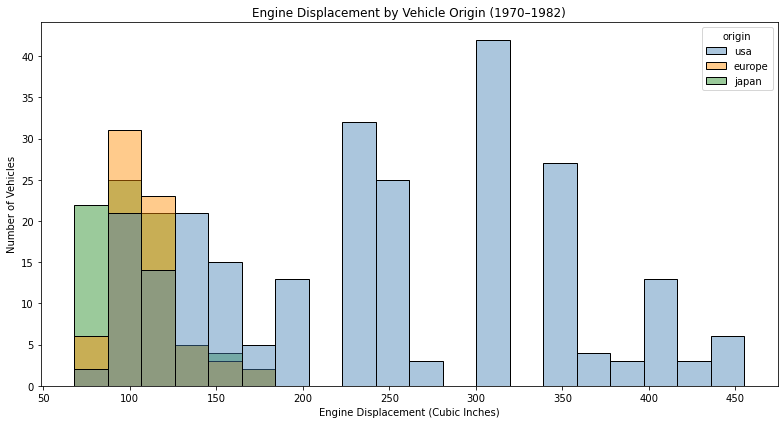

In [28]:
# Create and label the histogram comparison.
# Compare engine-displacement distributions by vehicle origin.
plt.figure(figsize=(11, 6))

sns.histplot(
    data=displacement_analysis_df,
    x="displacement",
    hue="origin",
    hue_order=origin_order,
    palette=origin_colors,
    bins=20,
    multiple="layer",
    alpha=0.45,
    common_bins=True
)

plt.title("Engine Displacement by Vehicle Origin (1970–1982)")
plt.xlabel("Engine Displacement (Cubic Inches)")
plt.ylabel("Number of Vehicles")

plt.tight_layout()
plt.show()

**From the histogram, estimate each group's typical values and spread. Describe shape, overlap, and unusual observations. How do group sizes affect the comparison?**

Your answer:  The histogram suggests that American automobiles generally have larger engine displacements than European and Japanese automobiles during the 1970–1982 period.

**USA:** Engine displacement appears widely distributed, with many vehicles concentrated around 200–350 cubic inches (in³). The distribution also contains smaller engines and some particularly large engines exceeding 400 in³. Several concentrations may reflect different engine configurations, including four-cylinder, six-cylinder, and eight-cylinder engines.

**Europe:** Most engine displacements appear concentrated around 80–150 in³, although several larger engines extend beyond this range. The distribution appears right-skewed, with most observations toward the lower end.

**Japan:** Most vehicles appear concentrated around 70–120 in³, with a smaller number of vehicles having substantially larger engines. Japanese automobiles generally have the smallest engine displacements, with a relatively narrow concentration compared with American vehicles.

There is substantial overlap between European and Japanese vehicles, particularly between approximately 80 and 130 in³. American vehicles also overlap with both groups at lower engine displacements.

The histogram suggests

In [30]:
# Display grouped .describe() summaries and calculate or display the IQR for each group.
# Calculate descriptive statistics for engine displacement by origin.
displacement_summary = displacement_analysis_df.groupby("origin")["displacement"].describe()

# Calculate the interquartile range (IQR).
displacement_summary["IQR"] = (
    displacement_summary["75%"] - displacement_summary["25%"]
)

# Display results in a consistent group order.
displacement_summary.loc[origin_order].round(2)

,count,mean,std,min,25%,50%,75%,max,IQR
origin,,,,,,,,,
usa,249.0,245.90,98.50,85.0,151.00,250.0,318.0,455.0,167.00
europe,70.0,109.14,22.58,68.0,92.25,104.5,121.0,183.0,28.75
japan,79.0,102.71,23.14,70.0,86.00,97.0,119.0,168.0,33.00


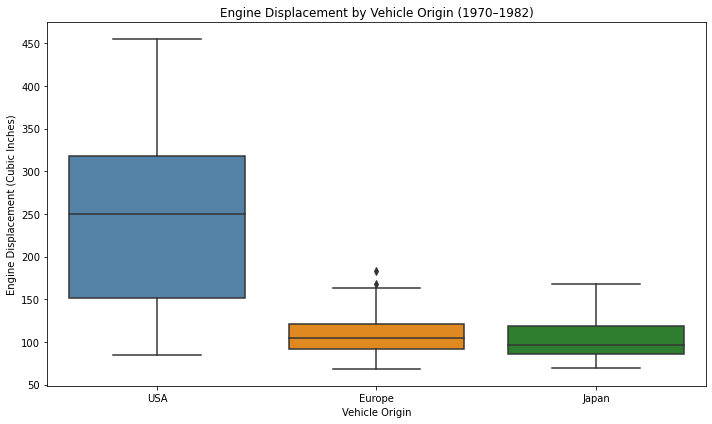

In [32]:
# Create and label the box-plot comparison.
# Compare engine-displacement distributions by vehicle origin.
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=displacement_analysis_df,
    x="origin",
    y="displacement",
    order=origin_order,
    palette=origin_colors
)

plt.title("Engine Displacement by Vehicle Origin (1970–1982)")
plt.xlabel("Vehicle Origin")
plt.ylabel("Engine Displacement (Cubic Inches)")
plt.xticks([0, 1, 2], ["USA", "Europe", "Japan"])

plt.tight_layout()
plt.show()

**How do the calculated summaries compare with your visual estimates? Which groups look similar or different? Cite centers and spreads with units, and explain what each plot reveals or hides.**

Your answer:  The calculated statistics support my prediction that American automobiles generally had larger engines than European and Japanese automobiles during the 1970–1982 period.

**USA (249 vehicles):**
- Mean: 245.90 cubic inches
- Median: 250.00 cubic inches
- Standard deviation: 98.50 cubic inches
- IQR: 167.00 cubic inches
- Range: 85–455 cubic inches

**Europe (70 vehicles):**
- Mean: 109.14 cubic inches
- Median: 104.50 cubic inches
- Standard deviation: 22.58 cubic inches
- IQR: 28.75 cubic inches
- Range: 68–183 cubic inches

**Japan (79 vehicles):**
- Mean: 102.71 cubic inches
- Median: 97.00 cubic inches
- Standard deviation: 23.14 cubic inches
- IQR: 33.00 cubic inches
- Range: 70–168 cubic inches

American vehicles had the largest median engine displacement at 250 cubic inches, approximately 153 cubic inches greater than the Japanese median and 145.50 cubic inches greater than the European median.

The American group also demonstrated substantially greater variability, with an IQR of 167 cubic inches. European and Japanese vehicles had more similar displacement distributions, with IQR values of 28.75 and 33 cubic inches, respectively.

The histogram reveals the overall distribution shapes, concentrations of engine sizes, and overlap among the three geographic groups. American vehicles show a much broader distribution, consistent with the variety of engine configurations represented in the dataset.

The box plot makes differences in medians, quartiles, and variability easier to compare. However, it does not reveal the individual concentrations and potential clusters of engine sizes as clearly as the histogram.

European and Japanese automobiles exhibit considerable overlap, particularly among smaller engines. American vehicles also overlap with both groups at lower displacements, although the American distribution extends much farther toward larger engines.

These results support my original prediction that American vehicles would generally have larger engines and greater variability. However, my prediction that European engines would fall substantially between American and Japanese engines was not fully supported. European and Japanese vehicles had relatively similar typical engine sizes.

Overall, these findings complement the previous investigations by showing that American vehicles in this historical dataset generally had larger engines, higher weights, and lower fuel efficiency. However, these comparisons do not establish that engine displacement alone caused the fuel-efficiency differences.

### Step 4: Check

Perform a sanity check connected to this question. Inspect original records for unusual values, verify any group boundaries or conversions, and reconcile group counts with the selected data. Consider plausible units, whether zero or negative values are valid, and whether the plotted range matches the numerical summary. Do not simply repeat the initial missing-value count.


In [33]:
# Perform a targeted check against original records or the declared group definitions.
# Verify group counts and engine-displacement measurements.
print("Vehicle counts by origin:")
print(vehicle_df["origin"].value_counts())

# Check for missing or invalid displacement measurements.
print("\nMissing displacement values:",
      vehicle_df["displacement"].isna().sum())

print("Zero or negative displacement values:",
      (vehicle_df["displacement"] <= 0).sum())

# Inspect the five vehicles with the smallest engines.
print("\nFive smallest engine displacements:")
display(
    vehicle_df.nsmallest(5, "displacement")[
        ["name", "origin", "model_year",
         "displacement", "cylinders", "mpg"]
    ]
)

# Inspect the five vehicles with the largest engines.
print("\nFive largest engine displacements:")
display(
    vehicle_df.nlargest(5, "displacement")[
        ["name", "origin", "model_year",
         "displacement", "cylinders", "mpg"]
    ]
)

# Confirm the number of analyzed observations.
print("\nTotal analyzed observations:",
      len(displacement_analysis_df))

Vehicle counts by origin:
usa       249
japan      79
europe     70
Name: origin, dtype: int64

Missing displacement values: 0
Zero or negative displacement values: 0

Five smallest engine displacements:


,name,origin,model_year,displacement,cylinders,mpg
117,fiat 128,europe,73,68.0,4,29.0
71,mazda rx2 coupe,japan,72,70.0,3,19.0
111,maxda rx3,japan,73,70.0,3,18.0
334,mazda rx-7 gs,japan,80,70.0,3,23.7
53,toyota corolla 1200,japan,71,71.0,4,31.0



Five largest engine displacements:


,name,origin,model_year,displacement,cylinders,mpg
8,pontiac catalina,usa,70,455.0,8,14.0
13,buick estate wagon (sw),usa,70,455.0,8,14.0
95,buick electra 225 custom,usa,73,455.0,8,12.0
6,chevrolet impala,usa,70,454.0,8,14.0
7,plymouth fury iii,usa,70,440.0,8,14.0



Total analyzed observations: 398


**What would make you suspicious, and why? What did your check establish? Describe any correction or unresolved uncertainty.**

Your answer  I performed a sanity check against the original Auto MPG records to verify that the engine-displacement measurements and geographic group assignments were reasonable.

I would be suspicious of missing displacement measurements, zero or negative displacement values, unexpected geographic categories, or unusually large or small engines that might indicate data-entry errors or incorrect measurement units.

The check confirmed that the dataset contains 249 American vehicles, 70 European vehicles, and 79 Japanese vehicles, totaling 398 observations. There were no missing, zero, or negative engine-displacement measurements.

I also inspected the five vehicles with the smallest engine displacements and the five with the largest, comparing their names, origins, model years, cylinder counts, and fuel-efficiency measurements.

The smallest engines were generally associated with smaller European and Japanese automobiles, while the largest engines were found among American vehicles. These results were consistent with the broader displacement distributions observed in the histogram and box plot.

No corrections, exclusions, or unit conversions were necessary for this investigation. However, the source documentation does not fully establish the original measurement and sampling procedures, so I cannot independently verify every recorded displacement value.

The analysis retains all 398 observations, including valid extreme measurements, while acknowledging these remaining uncertainties.

### Step 5: Conclusion


**Answer your research question using group sizes, center, spread, and overlap. Cite numerical evidence with units. How does it compare with your prediction?**

Your answer:  The analysis demonstrates substantial differences in engine-displacement distributions among American, European, and Japanese automobiles from the 1970–1982 model years.

**American vehicles (249 observations)** had the largest typical engine displacement, with a median of 250 cubic inches (in³), a mean of approximately 245.90 in³, and an interquartile range (IQR) of 167 in³.

**European vehicles (70 observations)** had a median displacement of 104.50 in³, a mean of approximately 109.14 in³, and an IQR of 28.75 in³.

**Japanese vehicles (79 observations)** had the smallest typical engine displacement, with a median of 97 in³, a mean of approximately 102.71 in³, and an IQR of 33 in³.

The American median displacement was 153 in³ greater than the Japanese median and 145.50 in³ greater than the European median.

American vehicles also demonstrated considerably greater variability in engine displacement, while European and Japanese automobiles had more similar distributions. Their median displacements differed by only 7.50 in³.

Although the American distribution extended toward much larger engines, the three regions showed overlap, particularly among smaller engine configurations. Therefore, geographic origin alone cannot accurately determine an individual vehicle's engine displacement.

The results largely support my original prediction that American automobiles would have the largest engines and greatest variability. However, European and Japanese vehicles had more similar typical engine sizes than I initially anticipated.

These findings also provide context for the previous investigations. American vehicles generally had larger engines, higher weights, and lower fuel efficiency in this dataset. These characteristics may be related, but the comparisons do not establish that engine displacement independently caused the

### Step 6: Limitation


**What should a reader avoid concluding, and why? Connect the limitation to this question and dataset.**

Your answer:  Although the analysis reveals substantial differences in engine displacement among American, European, and Japanese automobiles, several limitations must be considered.

First, the dataset covers model years 1970 through 1982. These findings describe historical automotive engineering and should not be generalized to modern vehicles or current manufacturing practices.

Second, the dataset is observational. Geographic origin does not independently determine engine displacement. Engine size can be influenced by vehicle class, intended use, performance requirements, manufacturer design decisions, and market preferences.

Third, the groups contain unequal numbers of observations: 249 American vehicles, 70 European vehicles, and 79 Japanese vehicles. This imbalance affects histogram counts and must be considered when comparing the distributions.

Additionally, the dataset includes different types of automobiles, ranging from compact cars to larger sedans, station wagons, and light trucks. Because the investigation does not control for vehicle class, some differences in engine displacement may reflect differences in the types of vehicles represented.

The original dataset documentation does not fully explain the sampling procedures or measurement methods. Therefore, I cannot assume these records represent every automobile produced in the three regions during this period.

Finally, larger engine displacement does not automatically mean greater horsepower or lower fuel efficiency. Those relationships depend on additional engineering factors that were not directly evaluated in this investigation.

**The supported conclusion is that engine-displacement distributions differ among geographic groups within this historical dataset, not that geographic origin causes those differences or that the findings apply universally.**

## AI-use reflection


**Did you use AI? If so, describe one suggestion you checked against your source, code, or output and what you accepted, modified, or rejected. If not, state that you did not use it.**

Your answer:  Yes, I used ChatGPT to assist with coding, troubleshooting, and interpreting the data.

I reviewed the suggestions against the assignment requirements and my notebook results, making adjustments when necessary. The final analysis was based on the dataset, calculations, and visualizations.

## Submission checklist

- Include the new dataset CSV, source citation, dictionary reference, and explanation of why it has not been used in class or a previous lab.
- Document every feature, including meaning, units/codes, conceptual type, storage type, and missing count.
- Identify at least one categorical feature and three distinct quantitative features.
- Complete three different questions, one quantitative feature per question, each with a prediction and all six workflow steps.
- Include a histogram and box plot for each question, grouped summaries and IQRs, and usable group sizes.
- Explain preparation and exclusions; preserve valid extreme values and distinguish missing values from zero.
- Support conclusions about similarities or differences with numerical and visual evidence, contextual checks, and specific limitations.
- Complete every written response and the AI-use reflection.
- Restart the kernel and run every cell in order; use relative paths and ensure all claims match the output.
